In [ ]:
pip install vaderSentiment

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 2.0 MB/s eta 0:00:00


In [ ]:
pip install --upgrade vaderSentiment

**Kunci Penilaian Sentimen VADER:**

neg: Skor negatif (nilai dari 0.0 sampai 1.0) menunjukkan seberapa negatif teks tersebut.

neu: Skor netral (nilai dari 0.0 sampai 1.0) menunjukkan seberapa netral teks tersebut.

pos: Skor positif (nilai dari 0.0 sampai 1.0) menunjukkan seberapa positif teks tersebut.

compound: Skor keseluruhan yang menggambarkan sentimen total dari teks, berkisar dari -1 (sangat negatif) hingga +1 (sangat positif).

In [ ]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
#note: depending on how you installed (e.g., using source code download versus pip install), you may need to import like this:
#from vaderSentiment import SentimentIntensityAnalyzer

# --- examples -------
sentences = ["VADER is smart, handsome, and funny.",  # positive sentence example
             "VADER is smart, handsome, and funny!",  # punctuation emphasis handled correctly (sentiment intensity adjusted)
             "VADER is very smart, handsome, and funny.", # booster words handled correctly (sentiment intensity adjusted)
             "VADER is VERY SMART, handsome, and FUNNY.",  # emphasis for ALLCAPS handled
             "VADER is VERY SMART, handsome, and FUNNY!!!", # combination of signals - VADER appropriately adjusts intensity
             "VADER is VERY SMART, uber handsome, and FRIGGIN FUNNY!!!", # booster words & punctuation make this close to ceiling for score
             "VADER is not smart, handsome, nor funny.",  # negation sentence example
             "The book was good.",  # positive sentence
             "At least it isn't a horrible book.",  # negated negative sentence with contraction
             "The book was only kind of good.", # qualified positive sentence is handled correctly (intensity adjusted)
             "The plot was good, but the characters are uncompelling and the dialog is not great.", # mixed negation sentence
             "Today SUX!",  # negative slang with capitalization emphasis
             "Today only kinda sux! But I'll get by, lol", # mixed sentiment example with slang and constrastive conjunction "but"
             "Make sure you :) or :D today!",  # emoticons handled
             "Catch utf-8 emoji such as such as 💘 and 😽 and 😁",  # emojis handled
             "Not bad at all"  # Capitalized negation
             ]

analyzer = SentimentIntensityAnalyzer()
for sentence in sentences:
    vs = analyzer.polarity_scores(sentence)
    print("{:-<65} {}".format(sentence, str(vs)))

VADER is smart, handsome, and funny.----------------------------- {'neg': 0.0, 'neu': 0.254, 'pos': 0.746, 'compound': 0.8316}
VADER is smart, handsome, and funny!----------------------------- {'neg': 0.0, 'neu': 0.248, 'pos': 0.752, 'compound': 0.8439}
VADER is very smart, handsome, and funny.------------------------ {'neg': 0.0, 'neu': 0.299, 'pos': 0.701, 'compound': 0.8545}
VADER is VERY SMART, handsome, and FUNNY.------------------------ {'neg': 0.0, 'neu': 0.246, 'pos': 0.754, 'compound': 0.9227}
VADER is VERY SMART, handsome, and FUNNY!!!---------------------- {'neg': 0.0, 'neu': 0.233, 'pos': 0.767, 'compound': 0.9342}
VADER is VERY SMART, uber handsome, and FRIGGIN FUNNY!!!--------- {'neg': 0.0, 'neu': 0.294, 'pos': 0.706, 'compound': 0.9469}
VADER is not smart, handsome, nor funny.------------------------- {'neg': 0.646, 'neu': 0.354, 'pos': 0.0, 'compound': -0.7424}
The book was good.----------------------------------------------- {'neg': 0.0, 'neu': 0.508, 'pos': 0.492, 'co

# Library

In [ ]:
!pip install google-play-scraper

import pandas as pd
import numpy as np
import nltk
from nltk.corpus import stopwords
from nltk.sentiment import SentimentIntensityAnalyzer
from google_play_scraper import app, Sort, reviews_all

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.9 MB/s eta 0:00:00


In [ ]:
def get_reviews(package_id):
  reviews = reviews_all(
    package_id,
    lang='id',
    country='id',
    sort=Sort.MOST_RELEVANT,
    count=2000,
    filter_score_with= None
  )

  # Mengubah hasil review menjadi DataFrame pandas dan mengembalikannya
  return pd.DataFrame(reviews)

Mengambil review dari aplikasi berdasarkan package_id. Aplikasi yang dipakai adalah Mobile Legend.

In [ ]:
# Mendefinisikan ID paket aplikasi yang akan diambil review-nya
PACKAGE_ID = 'com.mobile.legends'

# Mengambil review aplikasi berdasarkan PACKAGE_ID dan menyimpannya dalam variabel reviews
reviews = get_reviews(PACKAGE_ID)

# Menampilkan DataFrame reviews
reviews

,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion
0,b8952181-84db-4e6d-8109-5e5d223e6bc9,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,Tolong untuk update selanjutnya jaringannya le...,1,339,1.9.47.10372,2025-02-15 15:46:46,None,NaT,1.9.47.10372
1,c15c901e-ecd1-4726-b62a-c12941936cc9,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,"game nya bagus, grafiknya juga oke, tapi untuk...",4,101,1.9.47.10372,2025-02-13 08:47:45,None,NaT,1.9.47.10372
2,9ba3304c-1601-4303-94f9-da7596286529,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,"Moonton,tolong lahh,saya sering alami bug free...",3,18,1.9.47.10372,2025-02-15 06:29:27,None,NaT,1.9.47.10372
3,3b8b4628-068f-4404-8a35-e5bdc5c41822,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,"App perlu diperbaiki, dalam 1 hari bisa 5 kali...",1,399,1.9.47.10372,2025-02-13 17:05:43,None,NaT,1.9.47.10372
4,175c96cd-d4d4-4d0b-a645-c2c0dee49c03,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,"optimalisasi gameplay yang sangat buruk, tiba ...",1,76,1.9.47.10372,2025-02-14 09:40:49,None,NaT,1.9.47.10372
...,...,...,...,...,...,...,...,...,...,...,...
107995,0ff0bb85-3d13-4415-b501-5ba3ed1b60cb,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,Bingun mau ngomong apa sama game ini... Bisa g...,1,0,None,2024-05-01 13:00:59,None,NaT,None
107996,a45e9979-e020-45bb-ac51-1464eb860158,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,Moonton tolonglah di mode magic chess kapasita...,4,1,1.6.26.6851,2022-03-07 16:36:38,None,NaT,1.6.26.6851
107997,0af88c0f-5bcc-4f16-9cb8-b473dc81d6cd,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,"gak kasihan sama player solo?,tolong dong saya...",2,0,None,2024-07-10 06:47:44,None,NaT,None
107998,2edb199a-2396-4db5-a930-f7168212c6d6,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,Mengingat semakin canggihnya teknologi saat in...,3,0,1.6.85.7481,2023-10-29 08:07:46,None,NaT,1.6.85.7481


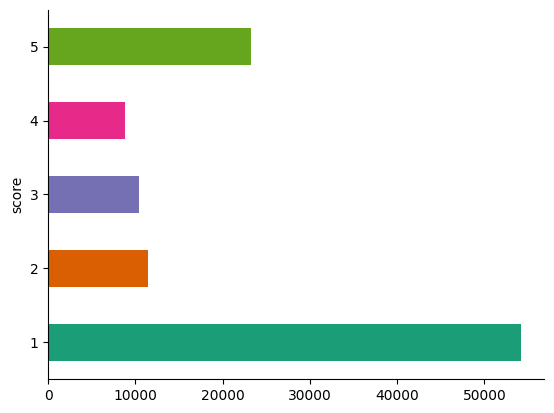

In [ ]:
# @title sentiment

from matplotlib import pyplot as plt
import seaborn as sns
reviews.groupby('score').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)

In [ ]:
# Menampilkan jumlah data reviews yang berhasil di ambil
len(reviews)

# Pre Processing Data

In [ ]:
# Memilih kolom 'content' dan 'score' dari DataFrame reviews
reviews = reviews[['content', 'score']]

# Menghapus baris yang memiliki nilai null
reviews = reviews.dropna()

# Menghapus semua karakter non-alfanumerik (kecuali spasi) dari kolom 'content'
reviews['clean_content'] = reviews['content'].str.replace('[^\w\s]', '')

# Mengubah semua teks dalam kolom 'clean_content' menjadi huruf kecil
reviews['clean_content'] = reviews['clean_content'].str.lower()

# Menampilkan kolom 'content', 'clean_content', dan 'score' dari DataFrame reviews
reviews[['content', 'clean_content', 'score']]

,content,clean_content,score
0,Tolong untuk update selanjutnya jaringannya le...,tolong untuk update selanjutnya jaringannya le...,1
1,"game nya bagus, grafiknya juga oke, tapi untuk...","game nya bagus, grafiknya juga oke, tapi untuk...",4
2,"Moonton,tolong lahh,saya sering alami bug free...","moonton,tolong lahh,saya sering alami bug free...",3
3,"App perlu diperbaiki, dalam 1 hari bisa 5 kali...","app perlu diperbaiki, dalam 1 hari bisa 5 kali...",1
4,"optimalisasi gameplay yang sangat buruk, tiba ...","optimalisasi gameplay yang sangat buruk, tiba ...",1
...,...,...,...
107995,Bingun mau ngomong apa sama game ini... Bisa g...,bingun mau ngomong apa sama game ini... bisa g...,1
107996,Moonton tolonglah di mode magic chess kapasita...,moonton tolonglah di mode magic chess kapasita...,4
107997,"gak kasihan sama player solo?,tolong dong saya...","gak kasihan sama player solo?,tolong dong saya...",2
107998,Mengingat semakin canggihnya teknologi saat in...,mengingat semakin canggihnya teknologi saat in...,3


In [ ]:
# Mendownload lexicon 'vader' yang digunakan untuk analisis sentimen
nltk.download('vader_lexicon')

# Membuat objek SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()

# Menghitung skor sentimen untuk setiap review dalam 'clean_content'
# Skor sentimen dihitung menggunakan metode polarity_scores dari SentimentIntensityAnalyzer
# Skor sentimen kemudian disimpan dalam kolom baru 'sentiment'
reviews['sentiment'] = reviews['clean_content'].apply(lambda x: sia.polarity_scores(x)['compound'])

# Mengubah skor sentimen menjadi label sentimen
# Jika skor > 0, labelnya adalah 'positif'
# Jika skor < 0, labelnya adalah 'negatif'
# Jika skor = 0, labelnya adalah 'netral'
reviews['sentiment'] = reviews['sentiment'].apply(lambda x: 'positif' if x > 0 else ('negatif' if x < 0 else 'netral'))

# Menampilkan kolom 'content' (isi review asli) dan 'sentiment' (label sentimen) dari DataFrame reviews
reviews[['content', 'sentiment']]

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


,content,sentiment
0,Tolong untuk update selanjutnya jaringannya le...,negatif
1,"game nya bagus, grafiknya juga oke, tapi untuk...",negatif
2,"Moonton,tolong lahh,saya sering alami bug free...",positif
3,"App perlu diperbaiki, dalam 1 hari bisa 5 kali...",negatif
4,"optimalisasi gameplay yang sangat buruk, tiba ...",positif
...,...,...
107995,Bingun mau ngomong apa sama game ini... Bisa g...,netral
107996,Moonton tolonglah di mode magic chess kapasita...,netral
107997,"gak kasihan sama player solo?,tolong dong saya...",netral
107998,Mengingat semakin canggihnya teknologi saat in...,netral


In [ ]:
reviews['score'].value_counts()

,count
score,
1,54143
5,23196
2,11429
3,10435
4,8797


<Axes: xlabel='score'>

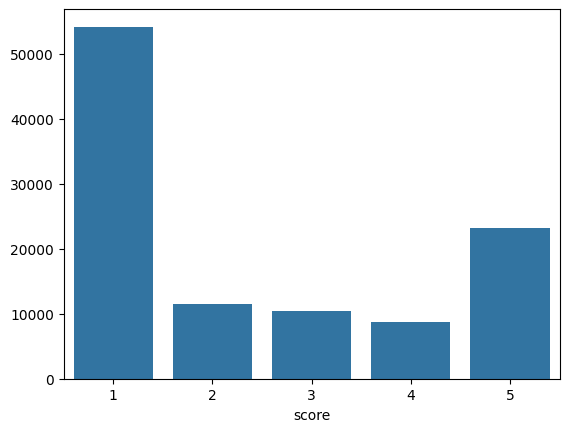

In [ ]:
import seaborn as sns
result = reviews.groupby(['score']).size()
# plot the result
sns.barplot(x = result.index, y = result.values)

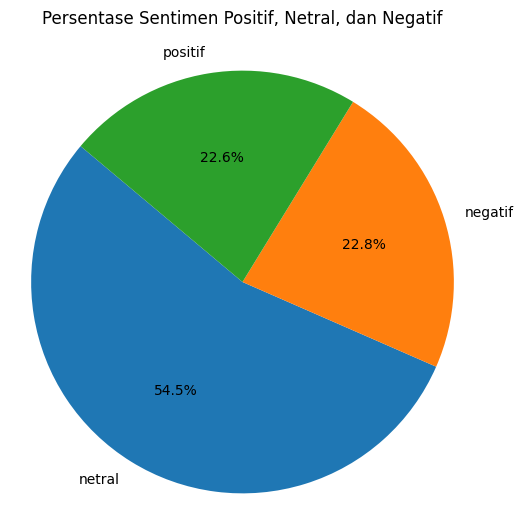

In [ ]:
import matplotlib.pyplot as plt

# Menghitung jumlah review untuk setiap sentimen
sentiment_counts = reviews['sentiment'].value_counts()

# Membuat plot pie
plt.figure(figsize=(6,6))
plt.pie(sentiment_counts, labels=sentiment_counts.index, autopct='%1.1f%%', startangle=140)
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

plt.title('Persentase Sentimen Positif, Netral, dan Negatif', pad=20)
plt.show()

# Pre Processing Text

In [ ]:
# Menghapus URL dari konten review
reviews['content'] = reviews['content'].str.replace('https\S+', ' ', case=False)

# Menghapus mention (@) dari konten review
reviews['content'] = reviews['content'].str.replace('@\S+', ' ', case=False)

# Menghapus hashtag (#) dari konten review
reviews['content'] = reviews['content'].str.replace('#\S+', ' ', case=False)

# Menghapus kontraksi kata (misalnya, "don't" menjadi "do not")
reviews['content'] = reviews['content'].str.replace("\'\w+", ' ', case=False)

# Menghapus tanda baca dari konten review
reviews['content'] = reviews['content'].str.replace("[^\w\s]", ' ', case=False)

# Menghapus angka yang merupakan '2' dalam teks (mungkin typo)
reviews['content'] = reviews['content'].str.replace("\s(2)", ' ', case=False)

# Mengimpor word_tokenize dari modul nltk
from nltk.tokenize import word_tokenize

# Mengimpor RegexpTokenizer dari nltk.tokenize
from nltk.tokenize import RegexpTokenizer

# Membuat instance RegexpTokenizer untuk hanya mempertahankan kata (alphanumeric)
regexp = RegexpTokenizer('\w+')

# Menerapkan tokenisasi pada kolom 'content'
reviews['content_token'] = reviews['content'].apply(regexp.tokenize)

# Menampilkan 3 baris pertama dari dataframe
reviews


,content,score,clean_content,sentiment,content_token
0,Tolong untuk update selanjutnya jaringannya le...,1,tolong untuk update selanjutnya jaringannya le...,negatif,"[Tolong, untuk, update, selanjutnya, jaringann..."
1,"game nya bagus, grafiknya juga oke, tapi untuk...",4,"game nya bagus, grafiknya juga oke, tapi untuk...",negatif,"[game, nya, bagus, grafiknya, juga, oke, tapi,..."
2,"Moonton,tolong lahh,saya sering alami bug free...",3,"moonton,tolong lahh,saya sering alami bug free...",positif,"[Moonton, tolong, lahh, saya, sering, alami, b..."
3,"App perlu diperbaiki, dalam 1 hari bisa 5 kali...",1,"app perlu diperbaiki, dalam 1 hari bisa 5 kali...",negatif,"[App, perlu, diperbaiki, dalam, 1, hari, bisa,..."
4,"optimalisasi gameplay yang sangat buruk, tiba ...",1,"optimalisasi gameplay yang sangat buruk, tiba ...",positif,"[optimalisasi, gameplay, yang, sangat, buruk, ..."
...,...,...,...,...,...
107995,Bingun mau ngomong apa sama game ini... Bisa g...,1,bingun mau ngomong apa sama game ini... bisa g...,netral,"[Bingun, mau, ngomong, apa, sama, game, ini, B..."
107996,Moonton tolonglah di mode magic chess kapasita...,4,moonton tolonglah di mode magic chess kapasita...,netral,"[Moonton, tolonglah, di, mode, magic, chess, k..."
107997,"gak kasihan sama player solo?,tolong dong saya...",2,"gak kasihan sama player solo?,tolong dong saya...",netral,"[gak, kasihan, sama, player, solo, tolong, don..."
107998,Mengingat semakin canggihnya teknologi saat in...,3,mengingat semakin canggihnya teknologi saat in...,netral,"[Mengingat, semakin, canggihnya, teknologi, sa..."


In [ ]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
# Make a list of Indonesian stopwords: menghapus kata yang sering muncul
stopwords = nltk.corpus.stopwords.words("indonesian")
# Extend the list with your own custom stopwords
my_stopwords = ['Mobile Legend']
stopwords.extend(my_stopwords)
# Remove stopwords
reviews['content_token'] = reviews['content_token'].apply(lambda x: [item for item in x if item not in stopwords])
reviews.head(5)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,content,score,clean_content,sentiment,content_token
0,Tolong untuk update selanjutnya jaringannya le...,1,tolong untuk update selanjutnya jaringannya le...,negatif,"[Tolong, update, jaringannya, perbaiki, bermai..."
1,"game nya bagus, grafiknya juga oke, tapi untuk...",4,"game nya bagus, grafiknya juga oke, tapi untuk...",negatif,"[game, nya, bagus, grafiknya, oke, matchmaking..."
2,"Moonton,tolong lahh,saya sering alami bug free...",3,"moonton,tolong lahh,saya sering alami bug free...",positif,"[Moonton, tolong, lahh, alami, bug, freeze, me..."
3,"App perlu diperbaiki, dalam 1 hari bisa 5 kali...",1,"app perlu diperbaiki, dalam 1 hari bisa 5 kali...",negatif,"[App, diperbaiki, 1, 5, kali, error, errornya,..."
4,"optimalisasi gameplay yang sangat buruk, tiba ...",1,"optimalisasi gameplay yang sangat buruk, tiba ...",positif,"[optimalisasi, gameplay, buruk, freeze, gamepl..."


In [ ]:
!pip install Sastrawi
# import Sastrawi package
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
# create stemmer: mengubah ke kata dasar
factory = StemmerFactory()
stemmer = factory.create_stemmer()
reviews['stemmed'] = reviews['content_token'].apply(lambda x: [stemmer.stem(y) for y in x]) # Stem every word.
reviews.head(5)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 4.1 MB/s eta 0:00:00


In [ ]:
reviews['text_string'] = reviews['stemmed'].apply(lambda x: ' '.join([item for item in x if len(item)>3]))
reviews.head(5)

In [ ]:
reviews['text_string'] = reviews['text_string'].astype('str')
reviews['text_string'] = reviews['text_string'].astype(pd.StringDtype())
reviews.dtypes

In [ ]:
df_p=reviews[reviews['sentiment']=='positif']
all_words_lem = ' '.join([word for word in df_p['text_string']])
%matplotlib inline
import matplotlib.pyplot as plt
from wordcloud import WordCloud
wordcloud = WordCloud(background_color='white', width=800, height=500, random_state=21, max_font_size=130).generate(all_words_lem)
plt.figure(figsize=(20, 10))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off');

In [ ]:
df_p=reviews[reviews['sentiment']=='netral']
all_words_lem = ' '.join([word for word in df_p['text_string']])
%matplotlib inline
import matplotlib.pyplot as plt
from wordcloud import WordCloud
wordcloud = WordCloud(background_color='white', width=800, height=500, random_state=21, max_font_size=130).generate(all_words_lem)
plt.figure(figsize=(20, 10))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off');

In [ ]:
df_p=reviews[reviews['sentiment']=='negatif']
all_words_lem = ' '.join([word for word in df_p['text_string']])
%matplotlib inline
import matplotlib.pyplot as plt
from wordcloud import WordCloud
wordcloud = WordCloud(background_color='white', width=800, height=500, random_state=21, max_font_size=130).generate(all_words_lem)
plt.figure(figsize=(20, 10))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off');

# Sentiment Analysis Menggunakan Random Forest, SVM dan Naive Bayes

In [ ]:
# Text Preprocessing & Cleaning
from sklearn.feature_extraction.text import TfidfVectorizer
from nltk.corpus import stopwords
import re
from wordcloud import WordCloud,STOPWORDS
from nltk import SnowballStemmer
from sklearn.model_selection import train_test_split # Split Data
from imblearn.over_sampling import SMOTE # Handling Imbalanced
# Model Building
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report , confusion_matrix , accuracy_score # Performance Metrics
# Data Visualization
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

In [ ]:
X = reviews['text_string']
y = reviews['sentiment']
tfid = TfidfVectorizer()
X_final =  tfid.fit_transform(X)

In [ ]:
# Handling imbalanced using SMOTE
smote = SMOTE()
x_sm,y_sm = smote.fit_resample(X_final,y)

In [ ]:
X_train , X_test , y_train , y_test = train_test_split(x_sm , y_sm , test_size=0.1,random_state=3)
#random forest
random_forest_classifier = RandomForestClassifier()
random_forest_classifier.fit(X_train,y_train)
random_forest_classifier_prediction =  random_forest_classifier.predict(X_test)
accuracy_score(random_forest_classifier_prediction,y_test)

0.8828235850543906

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Inisialisasi persentase data uji yang akan divariasikan
test_sizes = [0.1, 0.2, 0.3, 0.4, 0.5]

# Inisialisasi model klasifikasi (misalnya: RandomForestClassifier)
model = RandomForestClassifier()

# Inisialisasi list untuk menyimpan hasil akurasi untuk tiap kombinasi data train dan data test
accuracy_results = []

# Lakukan perulangan untuk setiap persentase data uji
for test_size in test_sizes:
    # Bagi data menjadi data train dan data test dengan persentase yang ditentukan
    X_train, X_test, y_train, y_test = train_test_split(x_sm, y_sm, test_size=test_size, random_state=3)

    # Melatih model menggunakan data train
    model.fit(X_train, y_train)

    # Melakukan prediksi menggunakan data test
    y_pred = model.predict(X_test)

    # Menghitung akurasi dan menyimpannya dalam list
    accuracy = accuracy_score(y_test, y_pred)

    # Menambahkan hasil akurasi ke dalam list
    accuracy_results.append((test_size, accuracy))

# Menampilkan hasil akurasi untuk setiap kombinasi persentase data uji
for test_size, accuracy in accuracy_results:
    print(f"Test Size: {test_size}, Accuracy: {accuracy}")


In [ ]:
svm = SVC()
svm.fit(X_train,y_train)
svm_prediction =  svm.predict(X_test)
accuracy_score(svm_prediction,y_test)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC

# Inisialisasi persentase data uji yang akan divariasikan
test_sizes = [0.1, 0.2, 0.3, 0.4, 0.5]

# Inisialisasi model klasifikasi (SVM)
model = SVC()

# Inisialisasi list untuk menyimpan hasil akurasi untuk tiap kombinasi data train dan data test
accuracy_results = []

# Lakukan perulangan untuk setiap persentase data uji
for test_size in test_sizes:
    # Bagi data menjadi data train dan data test dengan persentase yang ditentukan
    X_train, X_test, y_train, y_test = train_test_split(x_sm, y_sm, test_size=test_size, random_state=3)

    # Melatih model menggunakan data train
    model.fit(X_train, y_train)

    # Melakukan prediksi menggunakan data test
    y_pred = model.predict(X_test)

    # Menghitung akurasi dan menyimpannya dalam list
    accuracy = accuracy_score(y_test, y_pred)

    # Menambahkan hasil akurasi ke dalam list
    accuracy_results.append((test_size, accuracy))

# Menampilkan hasil akurasi untuk setiap kombinasi persentase data uji
for test_size, accuracy in accuracy_results:
    print(f"Test Size: {test_size}, Accuracy: {accuracy}")


In [ ]:
nb = MultinomialNB()
nb.fit(X_train,y_train)
nb_prediction =  nb.predict(X_test)
accuracy_score(nb_prediction,y_test)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import MultinomialNB

# Inisialisasi persentase data uji yang akan divariasikan
test_sizes = [0.1, 0.2, 0.3, 0.4, 0.5]

# Inisialisasi model klasifikasi (Naive Bayes)
model = MultinomialNB()

# Inisialisasi list untuk menyimpan hasil akurasi untuk tiap kombinasi data train dan data test
accuracy_results = []

# Lakukan perulangan untuk setiap persentase data uji
for test_size in test_sizes:
    # Bagi data menjadi data train dan data test dengan persentase yang ditentukan
    X_train, X_test, y_train, y_test = train_test_split(x_sm, y_sm, test_size=test_size, random_state=3)

    # Melatih model menggunakan data train
    model.fit(X_train, y_train)

    # Melakukan prediksi menggunakan data test
    y_pred = model.predict(X_test)

    # Menghitung akurasi dan menyimpannya dalam list
    accuracy = accuracy_score(y_test, y_pred)

    # Menambahkan hasil akurasi ke dalam list
    accuracy_results.append((test_size, accuracy))

# Menampilkan hasil akurasi untuk setiap kombinasi persentase data uji
for test_size, accuracy in accuracy_results:
    print(f"Test Size: {test_size}, Accuracy: {accuracy}")


In [ ]:
# initialize list of lists
data_akurasi = [[80,20,60.86,52.17,60.86], [60,40,67.39,52.17,54.34],[50,50,65.21,52.17,57.97],[40,60,70.65,58.69,59.78],[20,80,70.17,51.75,53.50]]

# Create the pandas DataFrame
df_akurasi = pd.DataFrame(data_akurasi, columns=['data_train', 'data_tes', 'random_fores', 'SVM', 'naive_bayes'])

# print dataframe.
df_akurasi


In [ ]:
plt.plot(df_akurasi['data_train'], df_akurasi['random_fores'], 'g', label='Random Forest')
plt.plot(df_akurasi['data_train'], df_akurasi['SVM'], 'r', label='SVM')
plt.plot(df_akurasi['data_train'], df_akurasi['naive_bayes'], 'y', label='Naive Bayes')
plt.xlabel('Jumlah Data Train dalam %', fontsize=18)
plt.ylabel('Nilai Akurasi dalam %', fontsize=16)
plt.legend()
plt.show()

In [ ]:
#sorting berdasarkan data train ascending
df_akurasi = df_akurasi.sort_values(by='data_train', ascending=True)
# set width of bar
barWidth = 0.3
fig = plt.subplots(figsize =(12, 8))

# Set position of bar on X axis
br1 = np.arange(len(df_akurasi['random_fores']))
br2 = [x + barWidth for x in br1]
br3 = [x + barWidth for x in br2]
# Make the plot
plt.bar(br1, df_akurasi['random_fores'], color ='orange', width = barWidth,
  edgecolor ='grey', label ='Random Forest')
plt.bar(br2, df_akurasi['SVM'], color ='b', width = barWidth,
  edgecolor ='grey', label ='svm')
plt.bar(br3, df_akurasi['naive_bayes'], color ='magenta', width = barWidth,
  edgecolor ='grey', label ='Naive Bayes')
plt.ylim(40, 90)
# Adding Xticks
plt.xlabel('Data Train dalam %', fontweight ='bold', fontsize = 15)
plt.ylabel('Akurasi dalam %', fontweight ='bold', fontsize = 15)
plt.xticks([r + barWidth for r in range(len(df_akurasi['random_fores']))],
  df_akurasi['data_train'])
plt.legend()
plt.show()

1. From the visualization of the line plot and bar plot sentiment analysis above, it can be concluded as follows:
2. The SVM algorithm has the lowest performance compared to the Naive Bayes and Random Forest algorithms
3. The Random Forest algorithm for 20–60% train data has the highest accuracy performance compared to the SVM and Naive Bayes algorithms.
4. The Random Forest algorithm with 80% train data has the same accuracy performance as the Naive Bayes algorithm.